In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
path = kagglehub.competition_download('filament-segmentation-2026')

print("Path to competition files:", path)
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/test/test_images/20220621185332Bh.jpeg
/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/test/test_images/20111208173814Mh.jpeg
/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/test/test_images/20200806072410Th.jpeg
/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/test/test_images/20111017113714Th.jpeg
/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/test/test_images/20170926225530Lh.jpeg
/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/test/test_images/20160327133734Ch.jpeg
/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/test/test_images/20160820233134Lh.jpeg
/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/test/test_images/20130310063154Uh.jpeg
/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.

In [2]:
!pip install -q segmentation-models-pytorch albumentations pycocotools scikit-image

In [3]:
import json, random
from collections import defaultdict
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch
import albumentations as A
import segmentation_models_pytorch as smp
from albumentations.pytorch import ToTensorV2
from pycocotools import mask as mask_utils
from scipy import ndimage
from skimage.measure import regionprops
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

CFG = dict(
    encoder="efficientnet-b3",
    crop_size=1024,     # train on full-resolution crops; predict on the whole 2048 image
    batch_size=4,       # lower to 2 if the GPU runs out of memory
    epochs=30,
    lr=3e-4,
    num_workers=2,
    seed=42,
)
# Post-processing in 2048px units, tuned on a held-out split in earlier experiments.
POST = dict(thr=0.4, merge_r=12, min_area=400, close_r=4, min_conf=0.85)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(CFG["seed"])

# Locate the dataset wherever Kaggle mounted it.
ANN_PATH = next(Path("/kaggle/input").rglob("MAGFiLO_1.0_Annotations_kaggle2026_train.json"))
BASE = ANN_PATH.parent.parent
TRAIN_IMG_DIR = BASE / "train/train_images"
TEST_IMG_DIR = BASE / "test/test_images"
print(DEVICE, BASE)

cuda /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026


In [4]:
with open(ANN_PATH) as f:
    coco = json.load(f)

images_by_id = {im["id"]: im for im in coco["images"]}
anns_by_image_id = defaultdict(list)
for ann in coco["annotations"]:
    anns_by_image_id[ann["image_id"]].append(ann)

def filament_rle(image_id):
    """All filaments of one annotator batch merged into one binary mask, kept as compact RLE."""
    im = images_by_id[image_id]
    polygons = [p for ann in anns_by_image_id[image_id] for p in ann["segmentation"]]
    if not polygons:
        return mask_utils.encode(np.zeros((im["height"], im["width"]), np.uint8, order="F"))
    return mask_utils.merge(mask_utils.frPyObjects(polygons, im["height"], im["width"]))

train_ids = list(images_by_id)
file_names = sorted({im["file_name"] for im in coco["images"]})
# Full-resolution images in RAM (~3 GB); masks stay as RLE and are decoded on the fly.
img_cache = {fn: cv2.imread(str(TRAIN_IMG_DIR / fn), cv2.IMREAD_GRAYSCALE) for fn in tqdm(file_names, desc="images")}
mask_rles = {iid: filament_rle(iid) for iid in tqdm(train_ids, desc="masks")}
print(f"{len(file_names)} images, {len(train_ids)} annotated samples")

images:   0%|          | 0/707 [00:00<?, ?it/s]

masks:   0%|          | 0/1154 [00:00<?, ?it/s]

707 images, 1154 annotated samples


In [5]:
NORM = A.Normalize(mean=(0.449,), std=(0.226,))  # ImageNet grey stats
train_tf = A.Compose([
    A.RandomCrop(CFG["crop_size"], CFG["crop_size"]),
    A.HorizontalFlip(), A.VerticalFlip(), A.RandomRotate90(),
    A.Affine(scale=(0.9, 1.1), rotate=(-15, 15), p=0.5),
    A.RandomBrightnessContrast(0.2, 0.2, p=0.5),
    A.RandomGamma(p=0.3),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
    NORM, ToTensorV2(),
])
test_tf = A.Compose([NORM, ToTensorV2()])

class FilamentDataset(Dataset):
    def __init__(self, image_ids, tf):
        self.ids, self.tf = image_ids, tf
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        iid = self.ids[i]
        img = img_cache[images_by_id[iid]["file_name"]]
        mask = mask_utils.decode(mask_rles[iid]).astype(np.float32)
        out = self.tf(image=img, mask=mask)
        return out["image"], out["mask"].unsqueeze(0)

train_dl = DataLoader(FilamentDataset(train_ids, train_tf), batch_size=CFG["batch_size"], shuffle=True,
                      num_workers=CFG["num_workers"], drop_last=True, pin_memory=True,
                      persistent_workers=True)

In [6]:
model = smp.Unet(CFG["encoder"], encoder_weights="imagenet", in_channels=1, classes=1).to(DEVICE)
bce = smp.losses.SoftBCEWithLogitsLoss()
dice = smp.losses.DiceLoss("binary", from_logits=True)
criterion = lambda logits, y: bce(logits, y) + dice(logits, y)

optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=CFG["lr"],
                                                total_steps=CFG["epochs"] * len(train_dl))
scaler = torch.amp.GradScaler(enabled=DEVICE == "cuda")

config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 49.3MB            

model.safetensors: downloading bytes:           |  0.00B            

In [7]:
for epoch in range(CFG["epochs"]):
    model.train(); total = 0
    for x, y in tqdm(train_dl, leave=False, desc=f"epoch {epoch}"):
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            loss = criterion(model(x), y)
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update(); scheduler.step()
        total += loss.item()
    print(f"epoch {epoch:02d}  loss {total / len(train_dl):.4f}")

torch.save(model.state_dict(), "unet_final.pth")

epoch 0:   0%|          | 0/288 [00:00<?, ?it/s]

epoch 00  loss 1.8488


epoch 1:   0%|          | 0/288 [00:00<?, ?it/s]

epoch 01  loss 1.5076


epoch 2:   0%|          | 0/288 [00:00<?, ?it/s]

epoch 02  loss 1.2812


... (50 outputs left out)

epoch 28:   0%|          | 0/288 [00:00<?, ?it/s]

epoch 28  loss 0.3158


epoch 29:   0%|          | 0/288 [00:00<?, ?it/s]

epoch 29  loss 0.3138


In [8]:
def disk(r):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))

def postprocess(prob, thr, merge_r, min_area, close_r, min_conf):
    """Probability map -> instance map (0 = background, k = k-th filament)."""
    mask = (prob > thr).astype(np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, disk(close_r))
    mask = ndimage.binary_fill_holes(mask).astype(np.uint8)
    _, labels = cv2.connectedComponents(cv2.dilate(mask, disk(merge_r)), connectivity=8)
    labels *= mask
    drop = [r.label for r in regionprops(labels, intensity_image=prob)
            if r.area < min_area or r.intensity_mean < min_conf]
    labels[np.isin(labels, drop)] = 0
    return labels

@torch.no_grad()
def predict(img_u8):
    """Flip-TTA filament probability map at the image's own resolution."""
    x = test_tf(image=img_u8)["image"][None].to(DEVICE)
    flips = [[], [-1], [-2], [-2, -1]]
    with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
        p = sum(torch.sigmoid(model(x.flip(f)).float()).flip(f) for f in flips) / len(flips)
    return p[0, 0].cpu().numpy()

model.eval()

Unet(
  (encoder): EfficientNetEncoder(
    (_conv_stem): Conv2dStaticSamePadding(
      1, 40, kernel_size=(3, 3), stride=(2, 2), bias=False
      (static_padding): ZeroPad2d((0, 1, 0, 1))
    )
    (_bn0): BatchNorm2d(40, eps=0.001, momentum=0.010000000000000009, affine=True, track_running_stats=True)
    (_blocks): ModuleList(
      (0): MBConvBlock(
        (_expand_conv): Identity()
        (_bn0): Identity()
        (_depthwise_conv): Conv2dStaticSamePadding(
          40, 40, kernel_size=(3, 3), stride=[1, 1], groups=40, bias=False
          (static_padding): ZeroPad2d((1, 1, 1, 1))
        )
        (_bn1): BatchNorm2d(40, eps=0.001, momentum=0.010000000000000009, affine=True, track_running_stats=True)
        (_se_reduce): Conv2dStaticSamePadding(
          40, 10, kernel_size=(1, 1), stride=(1, 1)
          (static_padding): Identity()
        )
        (_se_expand): Conv2dStaticSamePadding(
          10, 40, kernel_size=(1, 1), stride=(1, 1)
          (static_padding): Ident

In [9]:
def rle_counts(mask):
    return mask_utils.encode(np.asfortranarray(mask.astype(np.uint8)))["counts"].decode()

rows = []
for path in tqdm(sorted(TEST_IMG_DIR.glob("*.jpeg")), desc="test"):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    labels = postprocess(predict(img), **POST)
    ids = [k for k in np.unique(labels) if k != 0]
    for n, k in enumerate(ids, start=1):
        rows.append({"filament_id": f"{path.stem}_{n}", "segmentation_rle": rle_counts(labels == k)})
    if not ids:  # every test image needs at least one row
        rows.append({"filament_id": f"{path.stem}_1", "segmentation_rle": rle_counts(np.zeros_like(img))})

sub = pd.DataFrame(rows)
sub.to_csv("submission.csv", index=False)
print(sub.shape, sub.filament_id.str.rsplit("_", n=1).str[0].nunique(), "images")
sub.head()

test:   0%|          | 0/180 [00:00<?, ?it/s]

(1041, 2) 180 images


,filament_id,segmentation_rle
0,20110120105534Ch_1,]_^h22no13M6KO2N2N2MXP<2hoC0O101O1O0gPNLen15YQ...
1,20110120105534Ch_2,PkVo12mo12N000O0100O11N010O02O0O11O10O02O000O2...
2,20110130110334Ch_1,b_jd22mo13N6I2N3N2N5K02O1NmPNAfn1?XQNChn1>TQND...
3,20110214175414Mh_1,W]d[28fo14L2N3J6M201N101POVOhRNj0Vm1YOhRNi0Vm1...
4,20110214175414Mh_2,g]da22mo11O1000O0100N20001O00001O00001O01O010O...


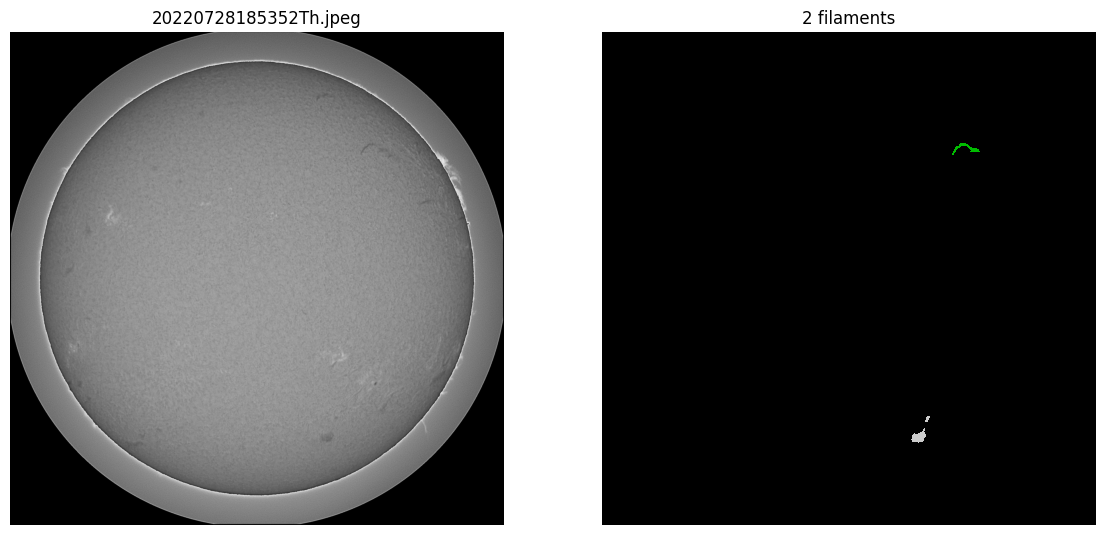

In [10]:
import matplotlib.pyplot as plt
# Sanity check on the last test image: input vs predicted filaments.
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(img, cmap="gray"); ax[0].set_title(path.name)
ax[1].imshow(labels, cmap="nipy_spectral", interpolation="nearest"); ax[1].set_title(f"{len(ids)} filaments")
for a in ax: a.axis("off")
plt.show()